# Previsão de Aprovação de Empréstimo

**Nome:** Eduardo Santos Birchal

**Matrícula:** 2024023970

**Email:** edubirchal@gmail.com

# Código

In [24]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    KBinsDiscretizer,
    OneHotEncoder,
    OrdinalEncoder,
    PolynomialFeatures,
    PowerTransformer,
    StandardScaler,
)

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Dados

In [25]:
COMPETITION_NAME = 'trab-1-aprendizado-de-maquina-a'
IS_KAGGLE = Path('/kaggle/input').exists()

if IS_KAGGLE:
    INPUT_DIR = Path('/kaggle/input/competitions') / COMPETITION_NAME
else:
    INPUT_DIR = Path('data')

TARGET_NAME = 'loan_status'

train_data = pd.read_csv(INPUT_DIR / 'train.csv')
test_data = pd.read_csv(INPUT_DIR / 'test.csv')

train_data.head()

,id,cliente_idade,cliente_renda_anual,cliente_moradia,cliente_tempo_emprego,emprestimo_finalidade,emprestimo_grau_risco,emprestimo_valor,emprestimo_taxa_juros,emprestimo_prop_renda,historico_inadimplencia_previa,historico_anos,loan_status
0,0,37,35000,ALUGUEL,0.0,EDUCACAO,B,6000,11.49,0.17,N,14,0
1,1,22,56000,PROPRIA,6.0,SAUDE,C,4000,13.35,0.07,N,2,0
2,2,29,28800,PROPRIA,8.0,PESSOAL,A,6000,8.90,0.21,N,10,0
3,3,30,70000,ALUGUEL,14.0,NEGOCIO,B,12000,11.11,0.17,N,5,0
4,4,22,60000,ALUGUEL,2.0,SAUDE,A,6000,6.92,0.10,N,3,0


In [26]:
numerical_vars = [
    'cliente_idade',
    'cliente_renda_anual',
    'cliente_tempo_emprego',
    'emprestimo_valor',
    'emprestimo_taxa_juros',
    'emprestimo_prop_renda',
    'historico_anos',
]

categorical_vars = [
    'cliente_moradia',
    'emprestimo_finalidade',
    'emprestimo_grau_risco',
    'historico_inadimplencia_previa',
]

discarded_vars = ['id']

In [27]:
X_train = train_data[numerical_vars + categorical_vars].copy()
y_train = train_data[TARGET_NAME].copy()
X_test = test_data[numerical_vars + categorical_vars].copy()

## EDA 

In [28]:
train_data.describe()

,id,cliente_idade,cliente_renda_anual,cliente_tempo_emprego,emprestimo_valor,emprestimo_taxa_juros,emprestimo_prop_renda,historico_anos,loan_status
count,58645.000000,58645.000000,5.864500e+04,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000
mean,29322.000000,27.550857,6.404617e+04,4.701015,9217.556518,10.677874,0.159238,5.813556,0.142382
std,16929.497605,6.033216,3.793111e+04,3.959784,5563.807384,3.034697,0.091692,4.029196,0.349445
min,0.000000,20.000000,4.200000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,0.000000
25%,14661.000000,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000,0.000000
50%,29322.000000,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000,0.000000
75%,43983.000000,30.000000,7.560000e+04,7.000000,12000.000000,12.990000,0.210000,8.000000,0.000000
max,58644.000000,123.000000,1.900000e+06,123.000000,35000.000000,23.220000,0.830000,30.000000,1.000000


cliente_idade e cliente_tempo_emprego têm valores máximos bastante absurdos... teremos que limitá-los para fins de plausibilidade

In [29]:
outliers_idade = pd.DataFrame({
    'treino': [
        (train_data['cliente_idade'] > 100).sum(),
        (train_data['cliente_tempo_emprego'] > 50).sum(),
        (train_data['cliente_tempo_emprego'] > train_data['cliente_idade'] - 16).sum(),
    ],
    'teste': [
        (test_data['cliente_idade'] > 100).sum(),
        (test_data['cliente_tempo_emprego'] > 50).sum(),
        (test_data['cliente_tempo_emprego'] > test_data['cliente_idade']).sum(),
    ],
}, index=['idade > 100', 'tempo_emprego > 50', 'tempo_emprego > idade'])

outliers_idade

,treino,teste
idade > 100,1,0
tempo_emprego > 50,2,0
tempo_emprego > idade,982,0


temos vários valores de tempo_emprego inválidos quando comparados com a idade

In [30]:
train_data[numerical_vars].skew()

cliente_idade             1.965497
cliente_renda_anual      10.457723
cliente_tempo_emprego     2.054430
emprestimo_valor          1.188578
emprestimo_taxa_juros     0.200020
emprestimo_prop_renda     0.917473
historico_anos            1.618503
dtype: float64

apenas emprestimo_taxa_juros parece estar razoavelmente próximo de uma normal. teremos que lidar com isso durante o pré-processamento

In [31]:
y_train.value_counts(normalize=True)

loan_status
0    0.857618
1    0.142382
Name: proportion, dtype: float64

loan_status é, como de se esperar, fortemente assimétrico

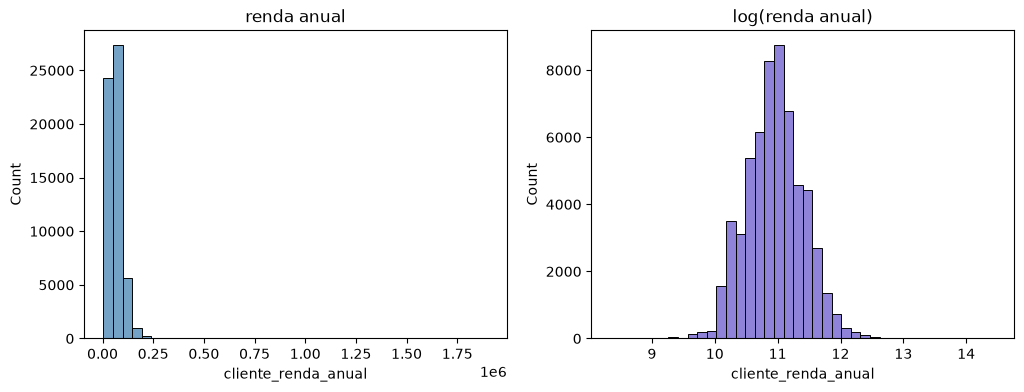

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

renda_anual = train_data['cliente_renda_anual']
sns.histplot(renda_anual, bins=40, ax=axes[0], color='steelblue')
axes[0].set_title('renda anual')

sns.histplot(np.log1p(renda_anual), bins=40, ax=axes[1], color='slateblue')
axes[1].set_title('log(renda anual)')

plt.show()

a distribuição de renda anual se aproxima bem melhor de uma normal quando seu log é tomado, como esperado

In [33]:
train_data[numerical_vars].apply(np.log1p).skew()

cliente_idade            1.198262
cliente_renda_anual      0.221843
cliente_tempo_emprego   -0.481416
emprestimo_valor        -0.458684
emprestimo_taxa_juros   -0.241043
emprestimo_prop_renda    0.724507
historico_anos           0.470231
dtype: float64

o mesmo vale pra maioria das outras variáveis

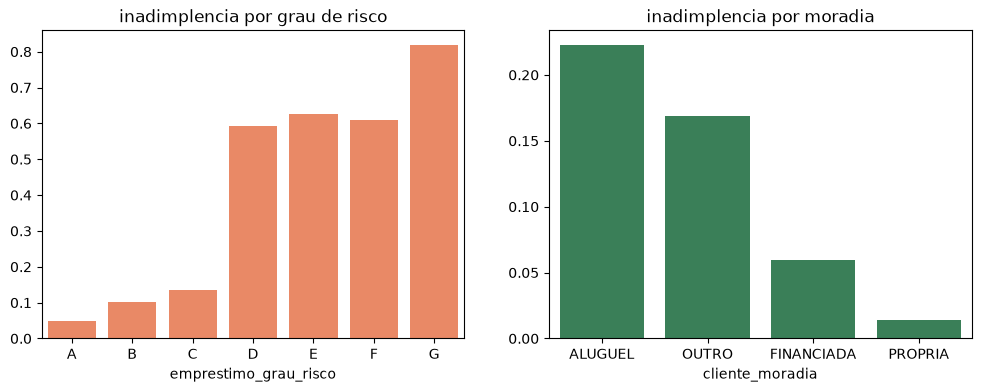

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

taxa_por_grau = train_data.groupby('emprestimo_grau_risco')[TARGET_NAME].mean().reindex(['A', 'B', 'C', 'D', 'E', 'F', 'G'])
sns.barplot(x=taxa_por_grau.index, y=taxa_por_grau.values, ax=axes[0], color='coral')
axes[0].set_title('inadimplencia por grau de risco')

taxa_por_moradia = train_data.groupby('cliente_moradia')[TARGET_NAME].mean().sort_values(ascending=False)
sns.barplot(x=taxa_por_moradia.index, y=taxa_por_moradia.values, ax=axes[1], color='seagreen')
axes[1].set_title('inadimplencia por moradia')

plt.show()

vemos que a inadimplência tem correlação bastante forte com o grau de risco e com a moradia do cliente

## Tratamento de Atributos

In [35]:
# ordens das categorias pra variáveis ordinais
order_emprestimo_grau_risco = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
order_historico_inadimplencia_previa = ['N', 'S']

In [36]:
class TratamentoAtributos(BaseEstimator, TransformerMixin):
    "corrige valores implausíveis e cria relações entre atributos"

    def fit(self, X, y=None):
        df = self._saneamento(X.copy())

        self.taxa_media_por_grau_ = (
            df.groupby('emprestimo_grau_risco')['emprestimo_taxa_juros'].mean().to_dict()
        )
        self.taxa_media_global_ = df['emprestimo_taxa_juros'].mean()

        return self

    def _saneamento(self, df):
        df['cliente_idade'] = df['cliente_idade'].clip(upper=100)

        limite_emprego = (df['cliente_idade']).clip(lower=0)
        df['cliente_tempo_emprego'] = np.minimum(df['cliente_tempo_emprego'], limite_emprego)

        return df

    def transform(self, X):
        df = self._saneamento(X.copy())

        df['renda_residual'] = (df['cliente_renda_anual'] - df['emprestimo_valor']).clip(lower=0)
        df['carga_juros_estimada'] = df['emprestimo_valor'] * (df['emprestimo_taxa_juros'] / 100.0)
        df['indice_carga_financeira'] = df['emprestimo_taxa_juros'] * df['emprestimo_prop_renda']
        df['maturidade_credito'] = df['historico_anos'] / df['cliente_idade']
        df['estabilidade_emprego'] = df['cliente_tempo_emprego'] / df['cliente_idade']

        taxa_esperada = df['emprestimo_grau_risco'].map(self.taxa_media_por_grau_).fillna(self.taxa_media_global_)
        df['desvio_taxa_grau'] = df['emprestimo_taxa_juros'] - taxa_esperada

        # faixas de comprometimento e de renda, já que essas variáveis sofrem mudanças bruscas
        faixa_prop = pd.cut(
            df['emprestimo_prop_renda'],
            bins=[-1, 0.15, 0.25, 0.30, 0.35, 10],
            labels=['p1', 'p2', 'p3', 'p4', 'p5'],
        ).astype(str)
        faixa_renda = pd.cut(
            df['cliente_renda_anual'],
            bins=[-1, 20000, 35000, 50000, 75000, 1e9],
            labels=['r1', 'r2', 'r3', 'r4', 'r5'],
        ).astype(str)

        # variáveis que representam combinações entre categóricas
        df['moradia_grau_risco'] = df['cliente_moradia'] + '_' + df['emprestimo_grau_risco']
        df['moradia_finalidade'] = df['cliente_moradia'] + '_' + df['emprestimo_finalidade']
        df['grau_finalidade'] = df['emprestimo_grau_risco'] + '_' + df['emprestimo_finalidade']
        df['moradia_grau_finalidade'] = df['moradia_grau_risco'] + '_' + df['emprestimo_finalidade']
        df['moradia_faixa_prop'] = df['cliente_moradia'] + '_' + faixa_prop
        df['moradia_faixa_renda'] = df['cliente_moradia'] + '_' + faixa_renda
        df['finalidade_faixa_renda'] = df['emprestimo_finalidade'] + '_' + faixa_renda
        df['moradia_grau_faixa_prop'] = df['moradia_grau_risco'] + '_' + faixa_prop
        
        return df

## Pré-processamento

In [37]:
cols_assimetricas = [
    'cliente_renda_anual',
    'emprestimo_valor',
    'renda_residual',
    'cliente_tempo_emprego',
    'historico_anos',
    'carga_juros_estimada',
    'emprestimo_prop_renda',
]

cols_continuas = [
    'cliente_idade',
    'emprestimo_taxa_juros',
    'emprestimo_prop_renda',
    'indice_carga_financeira',
    'maturidade_credito',
    'estabilidade_emprego',
    'desvio_taxa_grau',
]

cols_bins = [
    'emprestimo_prop_renda',
    'emprestimo_taxa_juros',
    'cliente_renda_anual',
]

cols_cruzadas = [
    'cliente_moradia',
    'emprestimo_finalidade',
    'emprestimo_grau_risco',
    'historico_inadimplencia_previa',
    'moradia_grau_risco',
    'moradia_finalidade',
    'grau_finalidade',
    'moradia_grau_finalidade',
    'moradia_faixa_prop',
    'moradia_faixa_renda',
    'finalidade_faixa_renda',
    'moradia_grau_faixa_prop',
]

In [38]:
def limitar_zscore(x):
    return np.clip(x, -5.0, 5.0)

def criar_preprocessador_logistica():
    pipe_assimetricas = Pipeline([
        ('log', FunctionTransformer(np.log1p)),
        ('sc1', StandardScaler()),
        ('clip1', FunctionTransformer(limitar_zscore)),
        ('poly', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
        ('sc2', StandardScaler()),
        ('clip2', FunctionTransformer(limitar_zscore)),
    ])
    pipe_continuas = Pipeline([
        ('sc1', StandardScaler()),
        ('clip1', FunctionTransformer(limitar_zscore)),
        ('poly', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
        ('sc2', StandardScaler()),
        ('clip2', FunctionTransformer(limitar_zscore)),
    ])
    pipe_ordinais = Pipeline([
        ('ord', OrdinalEncoder(categories=[order_emprestimo_grau_risco, order_historico_inadimplencia_previa])),
        ('sc', StandardScaler()),
    ])

    return ColumnTransformer([
        ('assimetricas', pipe_assimetricas, cols_assimetricas),
        ('continuas', pipe_continuas, cols_continuas),
        ('bins', KBinsDiscretizer(n_bins=12, strategy='quantile', encode='onehot', random_state=RANDOM_STATE), cols_bins),
        ('ordinais', pipe_ordinais, ['emprestimo_grau_risco', 'historico_inadimplencia_previa']),
        ('cruzadas', OneHotEncoder(drop=None, sparse_output=True, handle_unknown='ignore'), cols_cruzadas),
    ], sparse_threshold=1.0)

def criar_preprocessador_lda():
    pipe_log = Pipeline([
        ('log', FunctionTransformer(np.log1p)),
        ('sc', StandardScaler()),
    ])
    pipe_gauss = Pipeline([
        ('yj', PowerTransformer(method='yeo-johnson')), # essa transformação aproxima os dados de uma normal
        ('sc', StandardScaler()),
    ])

    return ColumnTransformer([
        ('assimetricas', pipe_log, cols_assimetricas),
        ('continuas', pipe_gauss, cols_continuas),
        ('bins', KBinsDiscretizer(n_bins=10, strategy='quantile', encode='onehot-dense', random_state=RANDOM_STATE), cols_bins),
        ('ordinais', OrdinalEncoder(categories=[order_emprestimo_grau_risco, order_historico_inadimplencia_previa]), ['emprestimo_grau_risco', 'historico_inadimplencia_previa']),
        ('cruzadas', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cols_cruzadas),
    ])

def criar_preprocessador_qda():
    pipe_log = Pipeline([
        ('log', FunctionTransformer(np.log1p)),
        ('sc', StandardScaler()),
    ])
    pipe_gauss = Pipeline([
        ('yj', PowerTransformer(method='yeo-johnson')),
        ('sc', StandardScaler()),
    ])

    return ColumnTransformer([
        ('assimetricas', pipe_log, cols_assimetricas),
        ('continuas', pipe_gauss, cols_continuas),
        ('ordinais', OrdinalEncoder(categories=[order_emprestimo_grau_risco, order_historico_inadimplencia_previa]), ['emprestimo_grau_risco', 'historico_inadimplencia_previa']),
        ('nominais', OneHotEncoder(drop='first', sparse_output=False), ['cliente_moradia', 'emprestimo_finalidade']),
    ])

## Modelagem

In [39]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def avaliar_modelo(modelo, X, y, cv=skf):
    scores = cross_val_score(modelo, X, y, cv=cv, scoring='average_precision')
    return scores.mean(), scores.std()

In [40]:
pipe_baseline = Pipeline([
    ('prep', ColumnTransformer([('num', StandardScaler(), numerical_vars)])),
    ('modelo', LogisticRegression(random_state=RANDOM_STATE, max_iter=300)),
])

media_base, std_base = avaliar_modelo(pipe_baseline, X_train, y_train)
print(f'baseline: pr auc = {media_base:.5f} +/- {std_base:.5f}')

baseline: pr auc = 0.57964 +/- 0.00911


In [41]:
candidatos = {
    'baseline': pipe_baseline,
    'ridge': Pipeline([
        ('fe', TratamentoAtributos()),
        ('prep', criar_preprocessador_logistica()),
        ('modelo', LogisticRegression(C=0.2, solver='lbfgs', max_iter=300, random_state=RANDOM_STATE)),
    ]),
    'ridge (class_weight balanced)': Pipeline([
        ('fe', TratamentoAtributos()),
        ('prep', criar_preprocessador_logistica()),
        ('modelo', LogisticRegression(C=0.2, class_weight='balanced', solver='lbfgs', max_iter=300, random_state=RANDOM_STATE)),
    ]),
    'lda': Pipeline([
        ('fe', TratamentoAtributos()),
        ('prep', criar_preprocessador_lda()),
        ('modelo', LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')),
    ]),
    'qda': Pipeline([
        ('fe', TratamentoAtributos()),
        ('prep', criar_preprocessador_qda()),
        ('modelo', QuadraticDiscriminantAnalysis(reg_param=0.01)),
    ]),
}

registros = []
for nome, pipe in candidatos.items():
    media, desvio = avaliar_modelo(pipe, X_train, y_train)
    registros.append({'modelo': nome, 'pr_auc_media': media, 'pr_auc_std': desvio})

tabela_comparacao = pd.DataFrame(registros).sort_values('pr_auc_media', ascending=False).reset_index(drop=True)
tabela_comparacao

,modelo,pr_auc_media,pr_auc_std
0,ridge,0.834511,0.012154
1,ridge (class_weight balanced),0.832409,0.010590
2,lda,0.821030,0.010540
3,qda,0.678440,0.005149
4,baseline,0.579645,0.009112


## Otimização

In [46]:
busca_lda = GridSearchCV(
    estimator=candidatos['lda'],
    param_grid={'modelo__shrinkage': [0, .005, .05, .1, .3, .5, .7, .9]},
    scoring='average_precision',
    cv=skf,
)
busca_lda.fit(X_train, y_train)
print(f'melhor qda: {busca_lda.best_params_} -> pr auc = {busca_lda.best_score_:.5f}')

busca_ridge = GridSearchCV(
    estimator=candidatos['ridge'],
    param_grid={'modelo__C': [0.05, 0.1, 0.2, 0.5, 1.0]},
    scoring='average_precision',
    cv=skf,
)
busca_ridge.fit(X_train, y_train)
print(f'melhor ridge: {busca_ridge.best_params_} -> pr auc = {busca_ridge.best_score_:.5f}')

melhor qda: {'modelo__shrinkage': 0.005} -> pr auc = 0.82635
melhor ridge: {'modelo__C': 0.2} -> pr auc = 0.83451


In [47]:
melhor_modelo = busca_ridge.best_estimator_

## Fazer a previsão

In [44]:
predictions = melhor_modelo.predict_proba(X_test)[:, 1]

## Salvar

In [45]:
submission = test_data[['id']].assign(**{TARGET_NAME: predictions})
submission.to_csv('submission.csv', index=False)
submission.head()

,id,loan_status
0,58645,0.998410
1,58646,0.022679
2,58647,0.757682
3,58648,0.014391
4,58649,0.089261
